# Hypothesis 4: Are cake sales higher on sunny days?

**Purpose:** This notebook tests hypothesis 4 from block 2 of the canvas (`CANVAS.md`):

> *On sunny days cake sales are higher.* (Owner: Britta)

The answer tells us whether sunshine (or cloud cover) is a useful input for forecasting the turnover of the cake group.

**Definitions (from `GLOSSARY.md`):**
- **Cakes** = product group `Warengruppe` 5.
- **Sunny day** = a day with cloud cover `Bewoelkung` ≤ 2 (in octas, 0 = clear … 8 = overcast). This is based on *observed* weather. The 12 cake days without cloud cover are filled from the neighbouring days first (section 1).
- **Sales** = turnover (`Umsatz`), not pieces.

**Comparison:** sunny vs. non-sunny days over the whole period, not within the same season (team decision, `DECISIONS.md` 2026-11-21). An overall difference can therefore partly reflect the season rather than the sun.

## Setup

Load the Python libraries we need. The data is read directly from the course repository (raw data is read-only).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu

DATA_URL = "https://raw.githubusercontent.com/opencampus-sh/intro-to-data-science-and-ml/main/data/bakery/"

# Weekdays are always ordered Monday to Sunday (team convention)
WEEKDAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

## 1. Load and join the data

We load the sales and the weather data and keep only the cake sales (group 5). Then we attach the weather to each cake day by date. This is a **left join**: every cake row is kept, even if the weather data has no row for that day (the cloud cover is then empty).

In [2]:
sales = pd.read_csv(DATA_URL + "umsatzdaten_gekuerzt.csv", parse_dates=["Datum"])
weather = pd.read_csv(DATA_URL + "wetter.csv", parse_dates=["Datum"])

# Check: the weather data has at most one row per day, so the join cannot duplicate cake rows
assert weather["Datum"].is_unique

cakes = sales[sales["Warengruppe"] == 5].copy()
cakes = cakes.merge(weather[["Datum", "Bewoelkung"]], on="Datum", how="left", indicator=True)

# Check: the join keeps every cake day (one row per sales day, 1,819 days)
assert len(cakes) == 1819
assert cakes["Datum"].is_unique
print(f"Cake rows: {len(cakes)}, from {cakes['Datum'].min():%d.%m.%Y} to {cakes['Datum'].max():%d.%m.%Y}")

Cake rows: 1819, from 01.07.2013 to 31.07.2018


### Check: missing cloud cover

A cake day can lack cloud cover for two reasons: the weather data has no row for that day at all, or the row exists but the cloud cover field is empty. We count both.

In [3]:
missing = cakes[cakes["Bewoelkung"].isna()]
no_weather_row = missing[missing["_merge"] == "left_only"]
empty_cloud = missing[missing["_merge"] == "both"]

print(f"Cake days without cloud cover: {len(missing)} of {len(cakes)} ({len(missing) / len(cakes):.1%})")
print(f"- no weather row at all ({len(no_weather_row)}):", no_weather_row["Datum"].dt.strftime("%d.%m.%Y").tolist())
print(f"- weather row, but cloud cover empty ({len(empty_cloud)}):", empty_cloud["Datum"].dt.strftime("%d.%m.%Y").tolist())

# Check: exactly the 12 known gaps (3 days without a weather row + 9 days in 30.10.-08.11.2017)
assert len(no_weather_row) == 3
assert len(empty_cloud) == 9
cakes = cakes.drop(columns="_merge")

Cake days without cloud cover: 12 of 1819 (0.7%)
- no weather row at all (3): ['11.12.2016', '04.10.2017', '05.10.2017']
- weather row, but cloud cover empty (9): ['30.10.2017', '01.11.2017', '02.11.2017', '03.11.2017', '04.11.2017', '05.11.2017', '06.11.2017', '07.11.2017', '08.11.2017']


### Fill the gaps from the neighbouring days

As decided in `DECISIONS.md` (2026-11-18, "Weather gaps and weather code"), the missing cloud cover is filled from the days just before and after each gap. We use **linear interpolation**: the missing days get values on a straight line between the last known day before the gap and the first known day after it, rounded to whole octas.

⚠️ For the long gap (30.10.–08.11.2017) the filled values are only a rough guess, so whether those days count as sunny is uncertain. This affects 9 of 1,819 days.

In [4]:
# Put the weather on a full calendar: one row per day, so the 3 days without a weather row appear as empty rows
cloud = weather.set_index("Datum")["Bewoelkung"]
full_days = pd.date_range(cloud.index.min(), cloud.index.max(), freq="D")
cloud = cloud.reindex(full_days)

# Fill each gap on a straight line between the day before and the day after, rounded to whole octas
cloud_filled = cloud.interpolate(method="time").round()

cakes["Bewoelkung_filled"] = cakes["Datum"].map(cloud_filled)

# Check: no cake day is left without cloud cover, and all values are valid octas (0-8)
assert cakes["Bewoelkung_filled"].notna().all()
assert cakes["Bewoelkung_filled"].between(0, 8).all()
# Check: days that had a value keep it unchanged
has_value = cakes["Bewoelkung"].notna()
assert (cakes.loc[has_value, "Bewoelkung"] == cakes.loc[has_value, "Bewoelkung_filled"]).all()

print("Filled values:")
print(cakes.loc[~has_value, ["Datum", "Bewoelkung_filled"]].to_string(index=False))

Filled values:
     Datum  Bewoelkung_filled
2016-12-11                7.0
2017-10-04                4.0
2017-10-05                2.0
2017-10-30                2.0
2017-11-01                3.0
2017-11-02                3.0
2017-11-03                4.0
2017-11-04                4.0
2017-11-05                5.0
2017-11-06                5.0
2017-11-07                5.0
2017-11-08                6.0


## 2. Mark sunny days

We add a new column `sunny` to the cake table: **1 = sunny day** (filled cloud cover ≤ 2 octas, see `GLOSSARY.md`), **0 = not sunny**. Every cake day gets exactly one of the two values.

In [5]:
cakes["sunny"] = (cakes["Bewoelkung_filled"] <= 2).astype(int)

# Check: only 0 and 1, and 1 exactly on the days with cloud cover <= 2
assert set(cakes["sunny"].unique()) <= {0, 1}
assert (cakes["sunny"] == 1).sum() == (cakes["Bewoelkung_filled"] <= 2).sum()

counts = cakes["sunny"].value_counts().sort_index()
print(f"Not sunny (0): {counts[0]} days ({counts[0] / len(cakes):.1%})")
print(f"Sunny (1):     {counts[1]} days ({counts[1] / len(cakes):.1%})")
cakes.head()

Not sunny (0): 1366 days (75.1%)
Sunny (1):     453 days (24.9%)


,id,Datum,Warengruppe,Umsatz,Bewoelkung,Bewoelkung_filled,sunny
0,1307015,2013-07-01,5,317.475875,6.0,6.0,0
1,1307025,2013-07-02,5,383.628682,3.0,3.0,0
2,1307035,2013-07-03,5,305.523072,7.0,7.0,0
3,1307045,2013-07-04,5,308.408168,7.0,7.0,0
4,1307055,2013-07-05,5,355.518770,5.0,5.0,0


## 3. Compare cake sales on sunny and non-sunny days

### Descriptive statistics

For each group (not sunny / sunny) we describe the daily cake turnover:
- **count**: number of days
- **mean**: average turnover per day
- **median**: the middle value (half of the days are below, half above). Less affected by a few extreme days than the mean.
- **std** (standard deviation): how far the days typically lie from the mean
- **min / 25% / 75% / max**: smallest value, quartiles (a quarter of the days below / above) and largest value

In [6]:
def describe_by_sunny(df):
    """Descriptive statistics of the daily cake turnover, split into not sunny (0) and sunny (1)."""
    stats = df.groupby("sunny")["Umsatz"].describe()
    stats = stats.rename(index={0: "not sunny (0)", 1: "sunny (1)"})
    # Check: the two groups together contain every day of the table
    assert stats["count"].sum() == len(df)
    return stats


def print_differences(stats):
    """Difference sunny minus not sunny, for the mean and the median."""
    for measure in ["mean", "50%"]:
        not_sunny = stats.loc["not sunny (0)", measure]
        sunny = stats.loc["sunny (1)", measure]
        name = "Mean" if measure == "mean" else "Median"
        print(f"{name}: sunny {sunny:.1f} vs. not sunny {not_sunny:.1f} "
              f"-> difference {sunny - not_sunny:+.1f} ({(sunny - not_sunny) / not_sunny:+.1%})")


stats = describe_by_sunny(cakes)
stats.round(1)

,count,mean,std,min,25%,50%,75%,max
sunny,,,,,,,,
not sunny (0),1366.0,274.9,109.8,121.5,223.4,262.6,305.3,1879.5
sunny (1),453.0,282.5,57.9,140.2,242.7,274.8,314.8,536.2


In [7]:
print_differences(stats)

Mean: sunny 282.5 vs. not sunny 274.9 -> difference +7.6 (+2.7%)
Median: sunny 274.8 vs. not sunny 262.6 -> difference +12.2 (+4.6%)


### Descriptive statistics without 2014-05-05

The 2014-05-05 value is removed, as decided in `DECISIONS.md` (2026-11-18, "Unusual values"): after a weekend with no sales it is about 2.5–3× a normal day in every group, so most likely 3 days were booked together. Keeping it would put one false extreme day into the comparison. From here on, the notebook uses the table without this day.

In [8]:
cakes_clean = cakes[cakes["Datum"] != "2014-05-05"].copy()

# Check: exactly one day removed, and it is gone
assert len(cakes_clean) == len(cakes) - 1
assert (cakes_clean["Datum"] != "2014-05-05").all()
print(f"Cake days: {len(cakes)} -> {len(cakes_clean)} after removing 2014-05-05")

stats_clean = describe_by_sunny(cakes_clean)
stats_clean.round(1)

Cake days: 1819 -> 1818 after removing 2014-05-05

,count,mean,std,min,25%,50%,75%,max
sunny,,,,,,,,
not sunny (0),1365.0,274.6,109.1,121.5,223.4,262.5,305.1,1879.5
sunny (1),453.0,282.5,57.9,140.2,242.7,274.8,314.8,536.2


In [9]:
print_differences(stats_clean)

Mean: sunny 282.5 vs. not sunny 274.6 -> difference +7.9 (+2.9%)
Median: sunny 274.8 vs. not sunny 262.5 -> difference +12.2 (+4.7%)


### Bar chart: median with 95% confidence interval (without 2014-05-05)

Each bar shows the **median** daily cake turnover of a group. The black line on top of each bar is the **95% confidence interval**: the range in which the true median very likely lies. If the intervals of sunny and non-sunny days barely overlap, the difference is unlikely to be chance.

We use the median rather than the mean because the 5 New Year's Eves (all not sunny) would pull the mean and its interval up. The median also matches the Mann-Whitney test below.

The interval is computed by **bootstrapping**: we draw the days of a group again at random (with replacement) 2,000 times, compute the median each time, and keep the middle 95% of these medians. The random seed is fixed so the result is the same on every run.

In [10]:
COLORS = {"not sunny": "#2a78d6", "sunny": "#eb6834"}  # colorblind-safe pair (blue / orange)
N_BOOTSTRAP = 2000


def median_with_ci(values, n_bootstrap=N_BOOTSTRAP, level=0.95, seed=42):
    """Median and bootstrap confidence interval (percentile method)."""
    rng = np.random.default_rng(seed)  # own fixed seed per call, so results do not depend on the call order
    values = values.to_numpy()
    resamples = rng.choice(values, size=(n_bootstrap, len(values)), replace=True)
    medians = np.median(resamples, axis=1)
    lower, upper = np.quantile(medians, [(1 - level) / 2, 1 - (1 - level) / 2])
    return np.median(values), lower, upper


overall_ci = pd.DataFrame(
    [
        dict(zip(["group", "median", "CI lower", "CI upper"],
                 [group, *median_with_ci(cakes_clean.loc[cakes_clean["sunny"] == flag, "Umsatz"])]))
        for group, flag in [("not sunny", 0), ("sunny", 1)]
    ]
).set_index("group")

# Check: every interval contains its median, and the medians match the descriptive statistics
assert ((overall_ci["CI lower"] <= overall_ci["median"]) & (overall_ci["median"] <= overall_ci["CI upper"])).all()
assert np.allclose(overall_ci["median"], stats_clean["50%"])

overall_ci.round(1)

,median,CI lower,CI upper
group,,,
not sunny,262.5,257.5,265.9
sunny,274.8,268.6,282.8


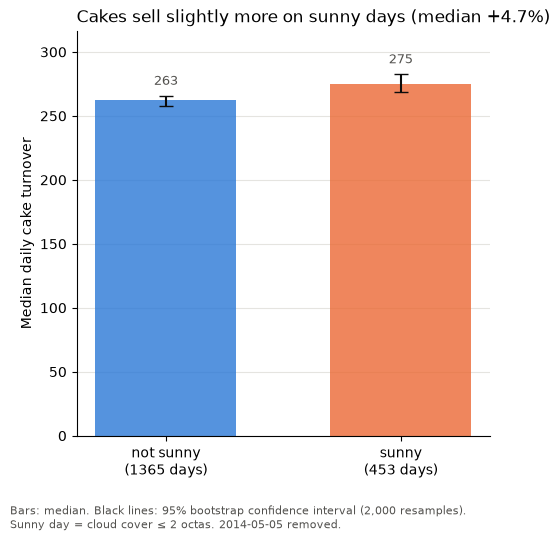

In [11]:
days = cakes_clean["sunny"].map({0: "not sunny", 1: "sunny"}).value_counts()
errors = [overall_ci["median"] - overall_ci["CI lower"], overall_ci["CI upper"] - overall_ci["median"]]

fig, ax = plt.subplots(figsize=(5, 5))
ax.bar(overall_ci.index, overall_ci["median"], width=0.6, color=[COLORS[g] for g in overall_ci.index], alpha=0.8)
ax.errorbar(overall_ci.index, overall_ci["median"], yerr=errors, fmt="none", ecolor="#0b0b0b", elinewidth=1.5, capsize=5)
for group, row in overall_ci.iterrows():
    ax.text(group, row["CI upper"] + 6, f"{row['median']:.0f}", ha="center", va="bottom", fontsize=9, color="#52514e")
ax.set_xticks(range(len(overall_ci)), [f"{group}\n({days[group]} days)" for group in overall_ci.index])

median_diff = overall_ci.loc["sunny", "median"] / overall_ci.loc["not sunny", "median"] - 1
ax.set_title(f"Cakes sell slightly more on sunny days (median {median_diff:+.1%})", loc="left", fontsize=12)
ax.set_ylabel("Median daily cake turnover")
ax.set_ylim(0, overall_ci["CI upper"].max() * 1.12)
ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.01, -0.02,
    "Bars: median. Black lines: 95% bootstrap confidence interval (2,000 resamples).\n"
    "Sunny day = cloud cover ≤ 2 octas. 2014-05-05 removed.",
    fontsize=8, color="#52514e", va="top",
)
plt.tight_layout()
plt.show()

### Mann-Whitney U test (without 2014-05-05)

The descriptive statistics show a small difference. The **Mann-Whitney U test** asks whether that difference could just be chance. It does not compare the turnover values themselves but their **ranks** (all days sorted from lowest to highest turnover), so a few extreme days such as New Year's Eve cannot dominate the result.

- **Null hypothesis:** cake turnover on sunny days is not higher than on non-sunny days.
- **Main test (one-sided):** the hypothesis names a direction (sunny days are *higher*), so we test that direction. For comparison we also report the two-sided test (sunny days are *different*, higher or lower).
- **p-value:** how likely a difference at least this large would be if the sun made no difference. We use the usual threshold of 5% (0.05).
- **Effect size:** the probability that a randomly chosen sunny day has a higher turnover than a randomly chosen non-sunny day. 50% means no difference.

⚠️ The test assumes that the days are independent of each other. Sales on neighbouring days are similar (e.g. within a season), so the p-value is probably somewhat too small, i.e. too optimistic.

In [12]:
sunny_sales = cakes_clean.loc[cakes_clean["sunny"] == 1, "Umsatz"]
not_sunny_sales = cakes_clean.loc[cakes_clean["sunny"] == 0, "Umsatz"]

# Check: the two groups together contain every day of the cleaned table
assert len(sunny_sales) + len(not_sunny_sales) == len(cakes_clean)

one_sided = mannwhitneyu(sunny_sales, not_sunny_sales, alternative="greater")
two_sided = mannwhitneyu(sunny_sales, not_sunny_sales, alternative="two-sided")

# Effect size: share of all (sunny day, non-sunny day) pairs in which the sunny day has the higher turnover
prob_sunny_higher = one_sided.statistic / (len(sunny_sales) * len(not_sunny_sales))

print(f"Days: sunny {len(sunny_sales)}, not sunny {len(not_sunny_sales)}")
print(f"U statistic: {one_sided.statistic:.0f}")
print(f"p-value, one-sided (sunny > not sunny): {one_sided.pvalue:.4g}")
print(f"p-value, two-sided (sunny != not sunny): {two_sided.pvalue:.4g}")
print(f"Probability that a random sunny day beats a random non-sunny day: {prob_sunny_higher:.1%}")

Days: sunny 453, not sunny 1365
U statistic: 353116
p-value, one-sided (sunny > not sunny): 2.828e-06
p-value, two-sided (sunny != not sunny): 5.655e-06
Probability that a random sunny day beats a random non-sunny day: 57.1%


## 4. Comparison within each season

Section 3 compared all sunny days with all non-sunny days. Part of that difference could come from the season rather than the sun (for example, if sunny days are more common in a season when people buy more cake anyway). Here we repeat the whole analysis **within each season** (team decision, `DECISIONS.md` 2026-11-21), on the cleaned data without 2014-05-05.

**Seasons** are the meteorological seasons used by weather services: **spring** = March–May, **summer** = June–August, **autumn** = September–November, **winter** = December–February.

First we add the season to every day and count how many sunny and non-sunny days each season has.

In [13]:
SEASON_ORDER = ["Spring", "Summer", "Autumn", "Winter"]
MONTH_TO_SEASON = {
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn",
    12: "Winter", 1: "Winter", 2: "Winter",
}
cakes_clean["season"] = cakes_clean["Datum"].dt.month.map(MONTH_TO_SEASON)

# Check: every day has a season
assert cakes_clean["season"].notna().all()

# Number of days per season and group (with totals)
pd.crosstab(cakes_clean["season"], cakes_clean["sunny"].map({0: "not sunny", 1: "sunny"}), margins=True).reindex(
    SEASON_ORDER + ["All"]
)

sunny,not sunny,sunny,All
season,,,
Spring,298,148,446
Summer,335,150,485
Autumn,350,103,453
Winter,382,52,434
All,1365,453,1818


### Descriptive statistics per season

The same statistics as in section 3, now for sunny and non-sunny days within each season, followed by the differences (sunny minus not sunny) in the mean and the median.

In [14]:
season_stats = pd.concat(
    {season: describe_by_sunny(cakes_clean[cakes_clean["season"] == season]) for season in SEASON_ORDER},
    names=["season", "group"],
)

# Check: all seasons together contain every day of the cleaned table
assert season_stats["count"].sum() == len(cakes_clean)

season_stats.round(1)

count   mean    std    min    25%    50%    75%     max
season group                                                                 
Spring not sunny (0)  298.0  259.6   54.4  153.7  220.6  250.0  287.6   450.7
       sunny (1)      148.0  263.6   55.5  140.2  227.2  259.4  287.6   495.5
Summer not sunny (0)  335.0  315.5   66.9  196.3  265.4  305.5  346.9   662.4
       sunny (1)      150.0  301.2   56.1  199.3  266.1  298.5  336.1   536.2
Autumn not sunny (0)  350.0  260.6   57.2  146.8  217.9  259.7  296.2   453.8
       sunny (1)      103.0  282.5   52.8  157.7  245.1  283.2  311.6   440.9
Winter not sunny (0)  382.0  263.1  177.2  121.5  203.3  237.2  276.7  1879.5
       sunny (1)       52.0  282.1   63.6  167.0  242.9  269.3  321.8   470.2

In [15]:
diff_rows = []
for season in SEASON_ORDER:
    st = season_stats.loc[season]
    row = {"season": season}
    for measure, name in [("mean", "mean"), ("50%", "median")]:
        not_sunny = st.loc["not sunny (0)", measure]
        sunny = st.loc["sunny (1)", measure]
        row[f"{name} not sunny"] = round(not_sunny, 1)
        row[f"{name} sunny"] = round(sunny, 1)
        row[f"{name} difference"] = f"{(sunny - not_sunny) / not_sunny:+.1%}"
    diff_rows.append(row)

pd.DataFrame(diff_rows).set_index("season")

,mean not sunny,mean sunny,mean difference,median not sunny,median sunny,median difference
season,,,,,,
Spring,259.6,263.6,+1.6%,250.0,259.4,+3.8%
Summer,315.5,301.2,-4.5%,305.5,298.5,-2.3%
Autumn,260.6,282.5,+8.4%,259.7,283.2,+9.1%
Winter,263.1,282.1,+7.2%,237.2,269.3,+13.6%


### Mann-Whitney U test per season

The same test as in section 3 (one-sided: sunny days higher; two-sided for comparison), now run separately in each season.

**Multiple testing:** with 4 tests instead of 1, the chance that at least one of them looks "significant" just by luck grows. The **Bonferroni correction** guards against this by dividing the threshold by the number of tests: 0.05 / 4 = **0.0125**. We report both thresholds.

⚠️ The same limit as before applies: neighbouring days are similar, so the p-values are probably somewhat too optimistic. The smaller groups per season also make the tests less able to detect a small effect.

In [16]:
BONFERRONI_THRESHOLD = 0.05 / len(SEASON_ORDER)

test_rows = []
for season in SEASON_ORDER:
    in_season = cakes_clean[cakes_clean["season"] == season]
    sunny_sales = in_season.loc[in_season["sunny"] == 1, "Umsatz"]
    not_sunny_sales = in_season.loc[in_season["sunny"] == 0, "Umsatz"]
    # Check: both groups have days in this season
    assert len(sunny_sales) > 0 and len(not_sunny_sales) > 0

    one_sided = mannwhitneyu(sunny_sales, not_sunny_sales, alternative="greater")
    two_sided = mannwhitneyu(sunny_sales, not_sunny_sales, alternative="two-sided")
    test_rows.append({
        "season": season,
        "days sunny": len(sunny_sales),
        "days not sunny": len(not_sunny_sales),
        "p one-sided": one_sided.pvalue,
        "p two-sided": two_sided.pvalue,
        "P(sunny day beats non-sunny day)": one_sided.statistic / (len(sunny_sales) * len(not_sunny_sales)),
    })

season_tests = pd.DataFrame(test_rows).set_index("season")
season_tests["higher at 5%"] = season_tests["p one-sided"] < 0.05
season_tests[f"higher at Bonferroni {BONFERRONI_THRESHOLD:.4f}"] = season_tests["p one-sided"] < BONFERRONI_THRESHOLD

season_tests.style.format({
    "p one-sided": "{:.2g}",
    "p two-sided": "{:.2g}",
    "P(sunny day beats non-sunny day)": "{:.1%}",
})

,days sunny,days not sunny,p one-sided,p two-sided,P(sunny day beats non-sunny day),higher at 5%,higher at Bonferroni 0.0125
season,,,,,,,
Spring,148,298,0.22,0.44,52.2%,False,False
Summer,150,335,0.97,0.062,44.7%,False,False
Autumn,103,350,0.00012,0.00023,61.9%,True,True
Winter,52,382,2.4e-05,4.9e-05,67.4%,True,True


### Bar chart per season: median with 95% confidence interval

The same kind of chart as in section 3, now per season: each bar shows the **median** daily cake turnover of a group in a season, and the black line on top is the **95% bootstrap confidence interval** (computed as in section 3). If the intervals of sunny and non-sunny days barely overlap, the difference is unlikely to be chance.

In [17]:
ci_rows = []
for season in SEASON_ORDER:
    in_season = cakes_clean[cakes_clean["season"] == season]
    for group, flag in [("not sunny", 0), ("sunny", 1)]:
        median, lower, upper = median_with_ci(in_season.loc[in_season["sunny"] == flag, "Umsatz"])
        ci_rows.append({"season": season, "group": group, "median": median, "CI lower": lower, "CI upper": upper})
season_ci = pd.DataFrame(ci_rows)

# Check: every interval contains its median, and the medians match the descriptive statistics
assert ((season_ci["CI lower"] <= season_ci["median"]) & (season_ci["median"] <= season_ci["CI upper"])).all()
for row in season_ci.itertuples():
    assert np.isclose(row.median, season_stats.loc[(row.season, f"{row.group} ({int(row.group == 'sunny')})"), "50%"])

season_ci.round(1)

,season,group,median,CI lower,CI upper
0,Spring,not sunny,250.0,243.0,256.2
1,Spring,sunny,259.4,248.9,265.2
2,Summer,not sunny,305.5,298.5,311.4
3,Summer,sunny,298.5,286.3,305.4
4,Autumn,not sunny,259.7,248.2,266.7
5,Autumn,sunny,283.2,266.2,291.6
6,Winter,not sunny,237.2,230.5,245.1
7,Winter,sunny,269.3,256.9,294.8


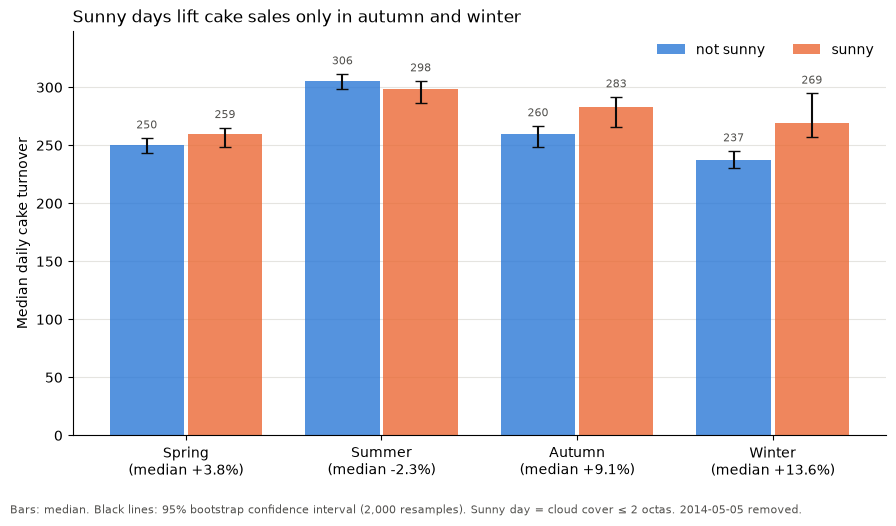

In [18]:
BAR_WIDTH = 0.38
x = np.arange(len(SEASON_ORDER))

fig, ax = plt.subplots(figsize=(9, 5))
for offset, group in [(-BAR_WIDTH / 2 - 0.01, "not sunny"), (BAR_WIDTH / 2 + 0.01, "sunny")]:
    data = season_ci[season_ci["group"] == group].set_index("season").loc[SEASON_ORDER]
    errors = [data["median"] - data["CI lower"], data["CI upper"] - data["median"]]
    ax.bar(x + offset, data["median"], width=BAR_WIDTH, color=COLORS[group], alpha=0.8, label=group)
    ax.errorbar(x + offset, data["median"], yerr=errors, fmt="none", ecolor="#0b0b0b", elinewidth=1.5, capsize=4)
    for xi, (median, upper) in zip(x + offset, zip(data["median"], data["CI upper"])):
        ax.text(xi, upper + 6, f"{median:.0f}", ha="center", va="bottom", fontsize=8, color="#52514e")

# Season labels with the median difference sunny vs. not sunny
medians = season_ci.pivot(index="season", columns="group", values="median").loc[SEASON_ORDER]
diffs = medians["sunny"] / medians["not sunny"] - 1
ax.set_xticks(x, [f"{season}\n(median {diff:+.1%})" for season, diff in diffs.items()])

# Title names the seasons in which sunny days are higher after the Bonferroni correction
significant = season_tests.index[season_tests[f"higher at Bonferroni {BONFERRONI_THRESHOLD:.4f}"]].str.lower().tolist()
title = (f"Sunny days lift cake sales only in {' and '.join(significant)}" if significant
         else "Sunny days do not clearly lift cake sales in any season")
ax.set_title(title, loc="left", fontsize=12)
ax.set_ylabel("Median daily cake turnover")
ax.set_ylim(0, season_ci["CI upper"].max() * 1.12)
ax.legend(frameon=False, loc="upper right", ncols=2)
ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.01, -0.02,
    "Bars: median. Black lines: 95% bootstrap confidence interval (2,000 resamples). "
    "Sunny day = cloud cover ≤ 2 octas. 2014-05-05 removed.",
    fontsize=8, color="#52514e", va="top",
)
plt.tight_layout()
plt.show()

## 5. Result

### Hypothesis 4 holds in autumn and winter, but not in spring and summer

**Answer:** Cake sales are higher on sunny days, but the effect depends on the season. In **autumn and winter** sunny days bring clearly more cake turnover (median about **+9%** and **+14%**). In **spring and summer** there is no clear difference.

**In one sentence for the operations manager:** *"On sunny autumn and winter days, plan roughly 10% more cake; in spring and summer the sun makes no reliable difference."* (This is an association, not proven cause; see the limits below.)

### Evidence

- **Overall** (section 3): sunny days have a median cake turnover **4.7% higher** than non-sunny days. The difference is very unlikely to be chance (Mann-Whitney U, one-sided p < 0.0001), but it is small: a randomly chosen sunny day beats a randomly chosen non-sunny day in only **57%** of cases (50% = no difference).
- **Per season** (section 4): the overall figure hides a clear seasonal pattern (see the table below).
  - **Autumn** (+9.1%) and **winter** (+13.6%): sunny days are higher, also after the stricter Bonferroni correction for 4 tests (p < 0.0125). A sunny day beats a non-sunny day in 62% (autumn) and 67% (winter) of cases.
  - **Spring** (+3.8%): not significant.
  - **Summer** (−2.3%): sunny days are, if anything, slightly *lower*. Not significant (two-sided p = 0.06).
- **Why the overall effect is smaller:** most sunny days fall in spring and summer, where the sun hardly helps. The clear effect in autumn and winter is diluted when all seasons are pooled.

### What this means for the forecast

Sunshine is worth trying as an input for the cake group (product group 5), but **not as a single fixed effect**: the model should be able to let the effect differ by season (e.g. an input "sunny × autumn/winter", or a model that learns interactions such as a neural network or tree model). Whether it actually improves the forecast has to be shown on the validation data against the baseline (canvas block 4).

### Limits

- **Association, not cause.** Within a season, sunny days may still fall more often on weekends, holidays (e.g. around Christmas) or warmer days. These were not separated here.
- **Winter rests on only 52 sunny days**, so its effect (+13.6%) is the least precise (95% confidence interval of the sunny median: about 257–295).
- **p-values are probably too optimistic**, because sales on neighbouring days are similar, while the test assumes independent days.
- **Observed weather, not forecasts.** In real planning only a weather forecast is available, which is less accurate, especially 7 days ahead (canvas block 6). The effect in a real forecast will be smaller.
- **Data decisions:** 2014-05-05 removed; 12 days with missing cloud cover filled from neighbouring days (2 of them count as sunny); sunny day = cloud cover ≤ 2 octas; meteorological seasons (all in `DECISIONS.md` and `GLOSSARY.md`).
- **Turnover, not pieces.** All results are in turnover; converting to pieces needs prices from the bakery.

### Next steps

1. Check whether the autumn/winter effect remains when weekday and public holidays are taken into account (e.g. in a regression with sunny × season, weekday and holiday as inputs).
2. Test sunshine (per season) as an input in the cake forecast and compare against the baseline on the validation data.

In [19]:
# Summary table, computed from the results above (overall and per season)
overall_test = mannwhitneyu(
    cakes_clean.loc[cakes_clean["sunny"] == 1, "Umsatz"],
    cakes_clean.loc[cakes_clean["sunny"] == 0, "Umsatz"],
    alternative="greater",
)
summary = season_ci.pivot(index="season", columns="group", values="median").loc[SEASON_ORDER]
summary.loc["All seasons"] = overall_ci["median"]
summary["median difference"] = summary["sunny"] / summary["not sunny"] - 1
summary["p one-sided"] = pd.concat([season_tests["p one-sided"], pd.Series({"All seasons": overall_test.pvalue})])
summary["P(sunny day beats non-sunny day)"] = pd.concat([
    season_tests["P(sunny day beats non-sunny day)"],
    pd.Series({"All seasons": prob_sunny_higher}),
])

summary.style.format({
    "not sunny": "{:.0f}",
    "sunny": "{:.0f}",
    "median difference": "{:+.1%}",
    "p one-sided": "{:.2g}",
    "P(sunny day beats non-sunny day)": "{:.1%}",
})

group,not sunny,sunny,median difference,p one-sided,P(sunny day beats non-sunny day)
season,,,,,
Spring,250,259,+3.8%,0.22,52.2%
Summer,306,298,-2.3%,0.97,44.7%
Autumn,260,283,+9.1%,0.00012,61.9%
Winter,237,269,+13.6%,2.4e-05,67.4%
All seasons,263,275,+4.7%,2.8e-06,57.1%
